***RePaint Sampling on DAS Patches***
**mixed DAS PATCHES**

In [1]:
import torch
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from utils.traffic_masks import line_mask
from pathlib import Path
from utils.das_dataset import DasDataset
from torch.utils.data import DataLoader
from utils.normalizer import denormalize

In [2]:
device= "cuda" if torch.cuda.is_available() else "cpu"
mask  = line_mask(h=256, w=512, s=(100,60), e=(400,150), r=4, device=device)
print(mask.shape, mask.device)

torch.Size([256, 512]) cuda:0


In [3]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_traffic_e = [das_data/"train_1111.h5"]
test_files_traffic_e = [das_data/"test_1111.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_traffic_e = DasDataset(train_files_traffic_e)
test_set_traffic_e = DasDataset(test_files_traffic_e)
train_loader_traffic_e = DataLoader(train_set_traffic_e, batch_size=16, shuffle=True)
test_loader_traffic_e = DataLoader(test_set_traffic_e, batch_size=16, shuffle=False)

In [ ]:
batch = next(iter(train_loader_traffic_e))
patch = batch [0:1].to(device)
print(patch.shape)

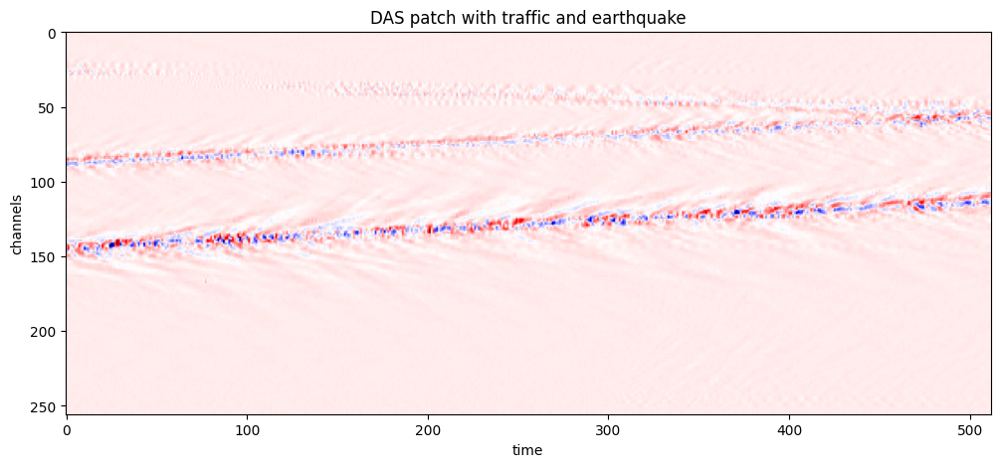

-18886.8203125 17503.234375


In [30]:
patch_denorm = denormalize(patch)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin, vmax = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with traffic and earthquake")
plt.show()
print(vmin, vmax)

In [ ]:
example_dir = Path("data/repaint_examples")
example_dir.mkdir(parents=True, exist_ok=True)
torch.save({"patch": patch.detach().cpu(),
            "desc": "Example for inpainting"},
            example_dir/"traffic_exp_01.pt")

In [8]:
example = torch.load("data/repaint_examples/traffic_exp_01.pt", map_location=device)
patch = example["patch"].to(device)
print(patch.shape)

torch.Size([1, 1, 256, 512])


In [4]:
import importlib
import utils.traffic_masks
importlib.reload(utils.traffic_masks)
from utils.traffic_masks import line_mask

In [12]:
def sample_repaint(model,scheduler,x0,mask,U=1, steps_to_save = [999,600,300,100,0]):
    with torch.no_grad():
        model.eval()
        B=x0.shape[0]
        T=scheduler.betas.shape[0]
        mask=mask.to(x0.device)
        xt=torch.rand_like(x0)
        snapshots = {}

        for step in reversed(range(T)):
            for u in range(U):
                t=torch.full((B,),step,device=x0.device,dtype=torch.long)
                predicted_noise=model(xt,t)
                xt_unknown,x0_pred=scheduler.reverse_sampling_step(xt,predicted_noise,step)
                if step>0:
                    gaussian_noise=torch.rand_like(x0)
                    t_prev=torch.full((B,),step-1,device=x0.device,dtype=torch.long)
                    x_known=scheduler.add_noise(x0,gaussian_noise,t_prev)
                else:
                    x_known=x0
                xt_prev=mask*x_known +(1.0-mask)*xt_unknown

                if(u == U-1) and (step in steps_to_save):
                    snapshots[step] = xt_prev.detach().clone()
                
                if(u<U-1) and (step>0):
                    z=torch.rand_like(xt_prev)
                    xt=torch.sqrt(scheduler.alphas[step]) * xt_prev +torch.sqrt(scheduler.betas[step])*z
                else: xt=xt_prev
        return xt, snapshots  

**STANDARD MSE MAMBA mixed**
*(mistake : unshuffled loaders)*

In [5]:
from models.unet_mamba import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_mb=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_mb_path= Path(checkpoints)/"das_ddpm_earthquake_model_mamba_50_50_mixed_normal_mse.pth"
checkpoint_model_mb = torch.load(model_mb_path, map_location = device)
model_mb.load_state_dict(checkpoint_model_mb["model_mb"])

<All keys matched successfully>

In [6]:
scheduler_E = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)

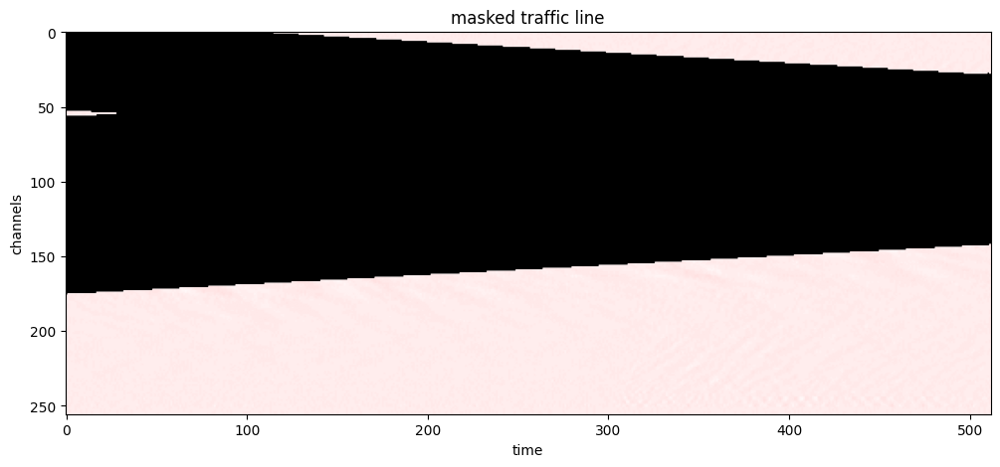

In [9]:
vmin = -18886.82
vmax = 17503.23
mask1  = line_mask(h=256, w=512, s=(0,145), e=(510,112), r=30, device=device)
mask2  = line_mask(h=256, w=512, s=(0,86), e=(510,57), r=30, device=device)
mask3  = line_mask(h=256, w=512, s=(0,22), e=(510,58), r=30, device=device)
mask_all = mask1*mask2*mask3
mask_all = mask_all.unsqueeze(0). unsqueeze(0)
missing_region = (mask_all[0,0] == 0).detach().cpu()
masked_patch = patch * mask_all
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin, vmax=vmax)
plt.imshow(missing_region, cmap="gray_r", aspect="auto", alpha = missing_region.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked traffic line")
plt.show()

In [16]:
result, snapshots = sample_repaint(model=model_mb, scheduler=scheduler_E, x0= patch, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

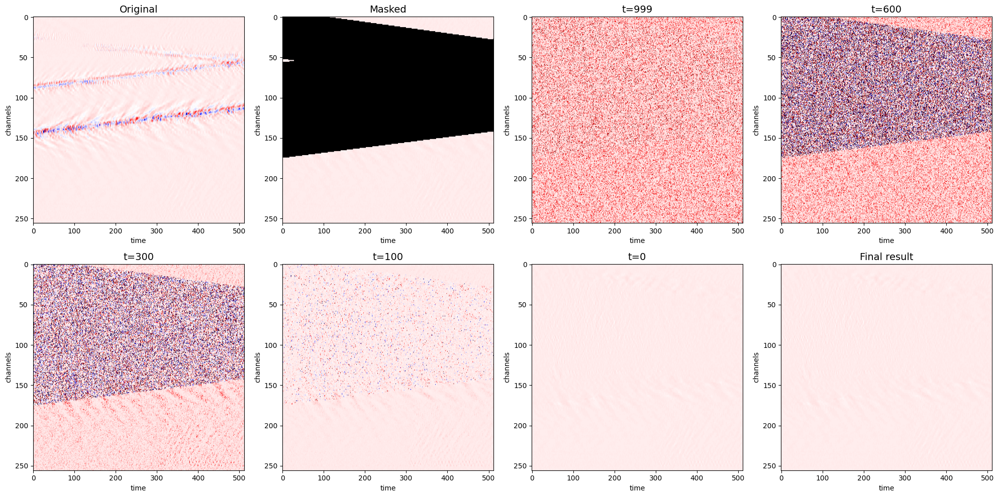

In [17]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

In [18]:
missing = mask_all == 0
result_denorm =  denormalize(result)
generated_region = result_denorm[missing]
print("generated masked region")
print("median abs:", generated_region.abs().median().item())
print("std:", generated_region.std().item())
print("99%:", torch.quantile(generated_region.abs(), 0.99).item())
print("99.9%:", torch.quantile(generated_region.abs(), 0.999).item())

generated masked region
median abs: 52.39360809326172
std: 85.5783920288086
99%: 251.65533447265625
99.9%: 363.9234924316406


torch.Size([1, 1, 256, 512])


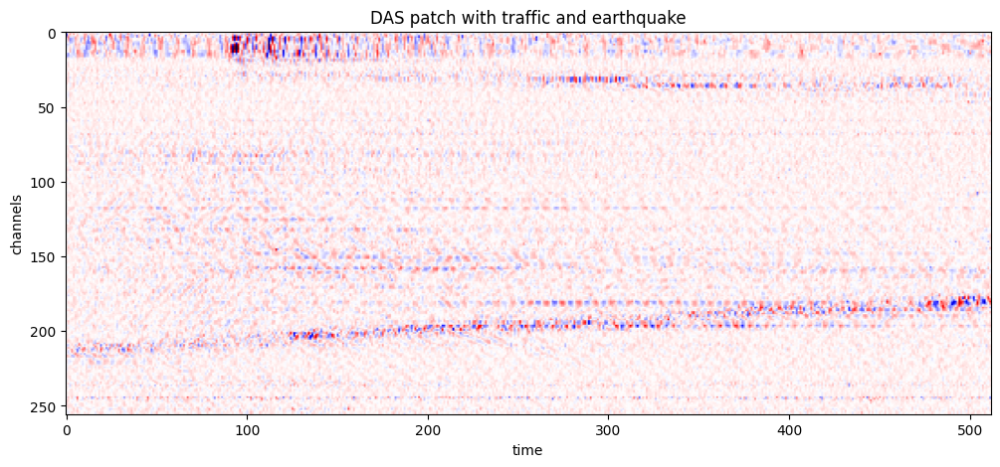

-8317.486328125 7938.90673828125


In [20]:
batch = next(iter(train_loader_traffic_e))
patch = batch [0:1].to(device)
print(patch.shape)
patch_denorm = denormalize(patch)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin, vmax = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with traffic and earthquake")
plt.show()
print(vmin, vmax)

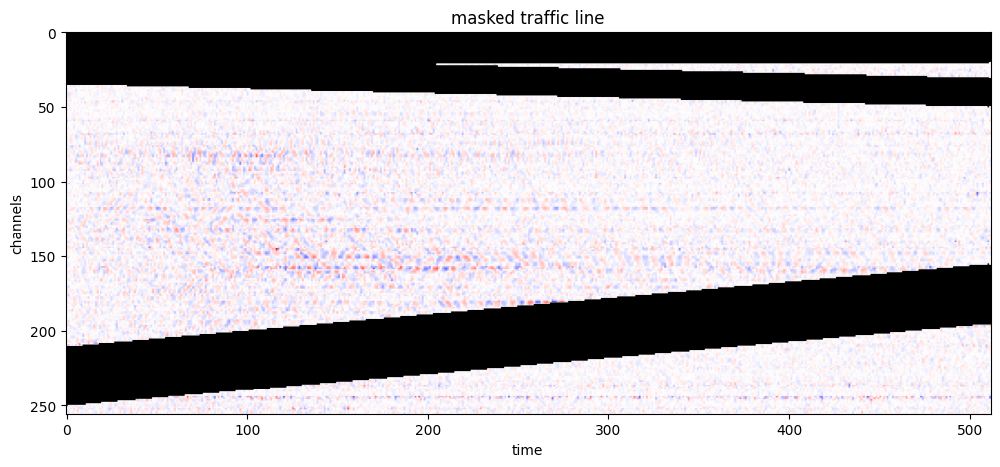

In [47]:
vmin = -8000
vmax = 8000
mask1  = line_mask(h=256, w=512, s=(0,230), e=(510,175), r=20, device=device)
mask2  = line_mask(h=256, w=512, s=(0,25), e=(510,40), r=10, device=device)
mask3  = line_mask(h=256, w=512, s=(0,5), e=(510,5), r=15, device=device)
mask_all = mask1*mask2*mask3
mask_all = mask_all.unsqueeze(0). unsqueeze(0)
missing_region = (mask_all[0,0] == 0).detach().cpu()
masked_patch = patch * mask_all
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin, vmax=vmax)
plt.imshow(missing_region, cmap="gray_r", aspect="auto", alpha = missing_region.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked traffic line")
plt.show()

In [24]:
example_dir = Path("data/repaint_examples")
example_dir.mkdir(parents=True, exist_ok=True)
torch.save({"patch": patch.detach().cpu(),
            "desc": "Example for inpainting 2"},
            example_dir/"traffic_exp_02.pt")

In [28]:
example2 = torch.load("data/repaint_examples/traffic_exp_02.pt", map_location=device)
patch2 = example2["patch"].to(device)
print(patch2.shape)

torch.Size([1, 1, 256, 512])


In [48]:
result2, snapshots2 = sample_repaint(model=model_mb, scheduler=scheduler_E, x0= patch2, mask=mask_all,U=1, steps_to_save = [999,600,300,100,0])

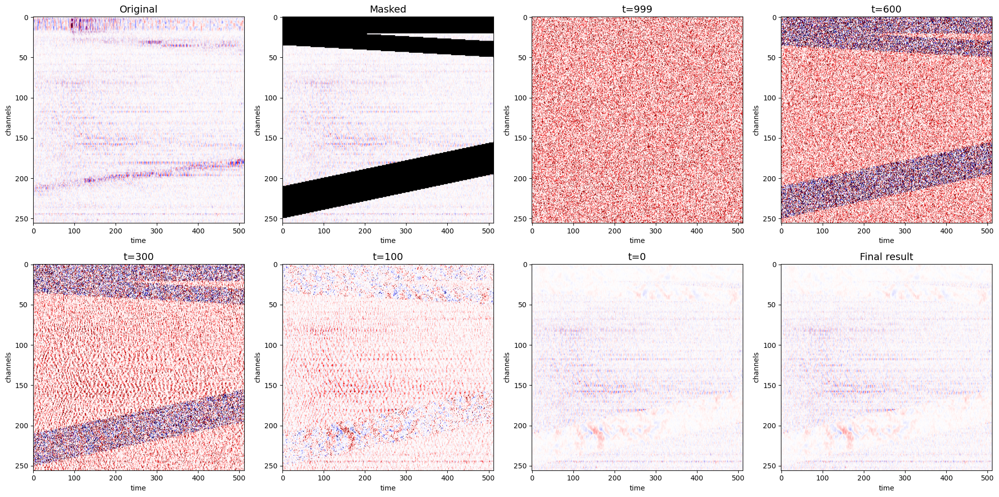

In [49]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch2)
masked_denorm = denormalize(masked_patch)
result_denorm = denormalize(result2)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots2[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**test on earthquake patch**

In [7]:
train_files_traffic_e0 = [das_data/"train_1001.h5"]
test_files_traffic_e0 = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_traffic_e0 = DasDataset(train_files_traffic_e0)
test_set_traffic_e0 = DasDataset(test_files_traffic_e0)
train_loader_traffic_e0 = DataLoader(train_set_traffic_e0, batch_size=16, shuffle=True)
test_loader_traffic_e0 = DataLoader(test_set_traffic_e0, batch_size=16, shuffle=False)

In [11]:
batch0 = next(iter(train_loader_traffic_e0))
patch0 = batch0 [0:1].to(device)
print(patch0.shape)

torch.Size([1, 1, 256, 512])


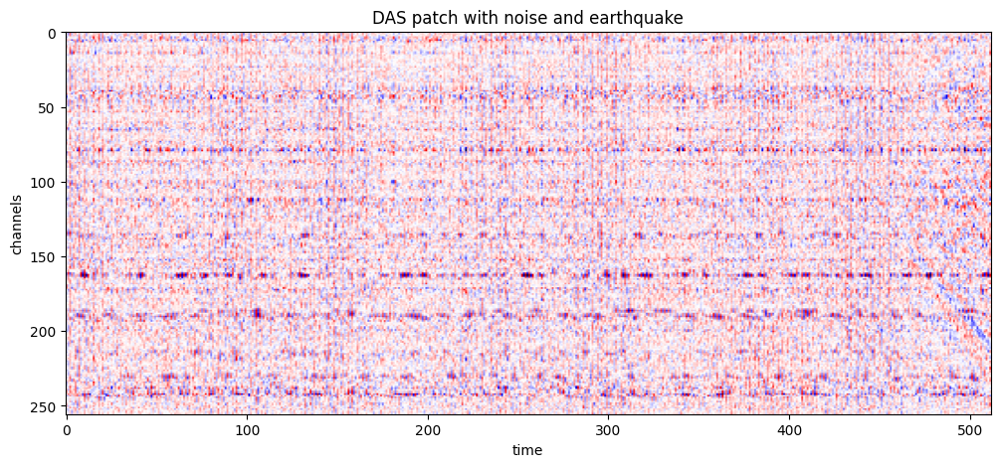

-409.0985412597656 386.85205078125


In [61]:
patch_denorm0 = denormalize(patch0)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm0[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin0, vmax0 = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with noise and earthquake")
plt.show()
print(vmin0, vmax0)

In [ ]:
example_dir = Path("data/repaint_examples")
example_dir.mkdir(parents=True, exist_ok=True)
torch.save({"patch": patch0.detach().cpu(),
            "desc": "Example for inpainting 3 earthquake and noise only"},
            example_dir/"earthquake_exp_01.pt")

In [7]:
example3 = torch.load("data/repaint_examples/earthquake_exp_01.pt", map_location=device)
patch3 = example3["patch"].to(device)
print(patch3.shape)

torch.Size([1, 1, 256, 512])


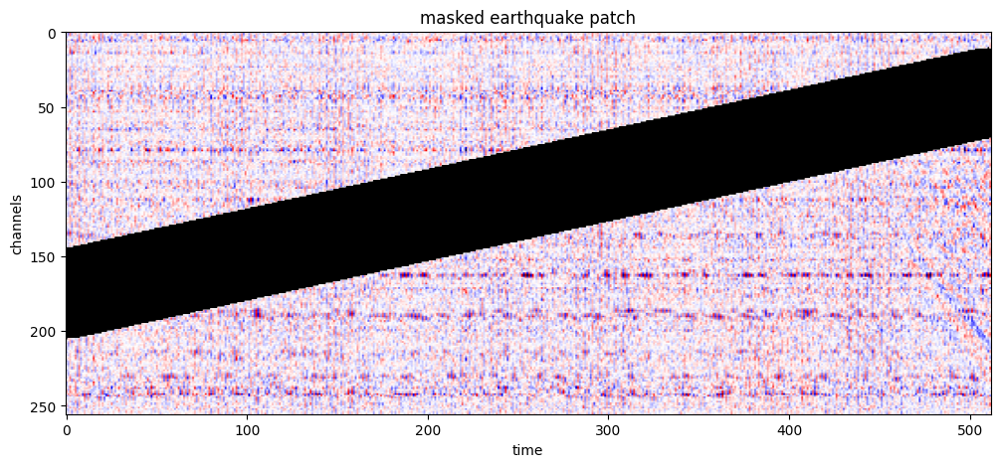

In [8]:
vmin0 = -400
vmax0 = 400
mask0  = line_mask(h=256, w=512, s=(0,175), e=(510,40), r=30, device=device)
missing_region0 = (mask0== 0).detach().cpu()
masked_patch3 = patch3 * mask0
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch3)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin0, vmax=vmax0)
plt.imshow(missing_region0, cmap="gray_r", aspect="auto", alpha = missing_region0.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked earthquake patch")
plt.show()

In [72]:
result3, snapshots3 = sample_repaint(model=model_mb, scheduler=scheduler_E, x0= patch3, mask=mask0,U=1, steps_to_save = [999,600,300,100,0])

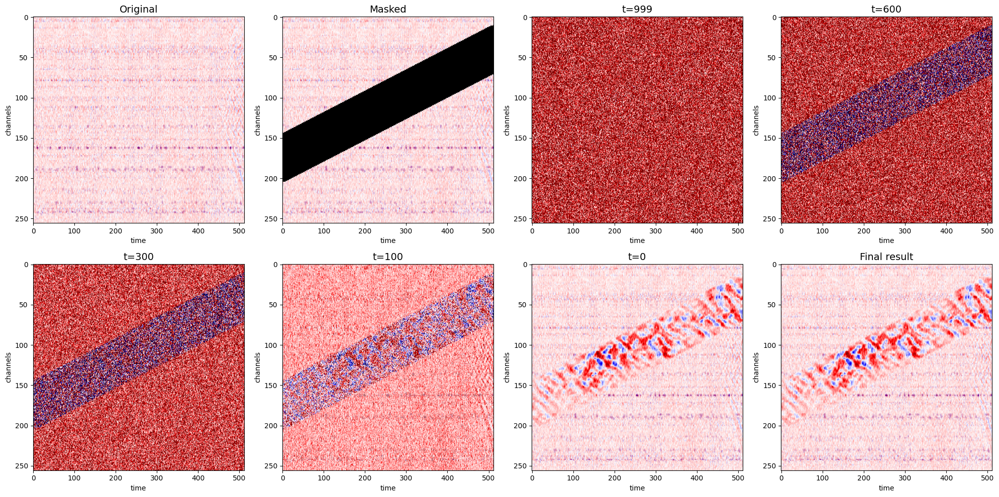

In [69]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result3)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(steps_to_show):

    snap_denorm = denormalize(snapshots3[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**Repaint with a jumping schedule**

In [11]:
import importlib
import utils.repaint as repaint
importlib.reload(repaint)

<module 'utils.repaint' from '/home/islem.dhouioui/ddpm/notebooks/../utils/repaint.py'>

In [12]:
times=repaint.repaint_schedule(10,1,3)
print(times)

[9, 8, 9, 8, 9, 8, 7, 8, 7, 8, 7, 6, 7, 6, 7, 6, 5, 6, 5, 6, 5, 4, 5, 4, 5, 4, 3, 4, 3, 4, 3, 2, 3, 2, 3, 2, 1, 2, 1, 2, 1, 0, 1, 0, 1, 0, -1]


jump_length=1, jump_n_sample=3

In [28]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result4, snaps4, times4 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=3, steps_to_save=[999, 600, 300, 100, 0])

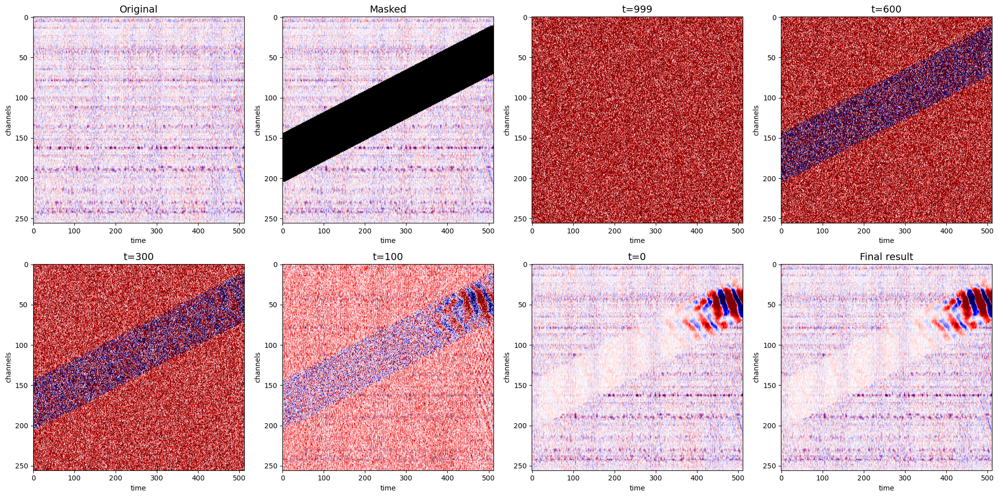

In [ ]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result4)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps4):

    snap_denorm = denormalize(snaps4[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jump_n_sample=10

In [31]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result5, snaps5, times5 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=10, steps_to_save=[999, 600, 300, 100, 0])

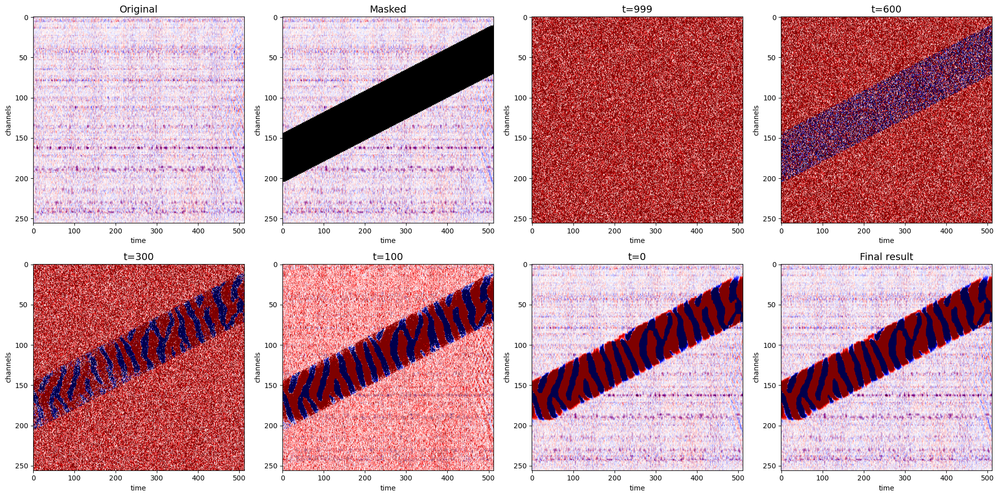

In [32]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result5)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps5):

    snap_denorm = denormalize(snaps5[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jump_n_sample=5

In [15]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result6, snaps6, times6 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=5, steps_to_save=[999, 600, 300, 100, 0])

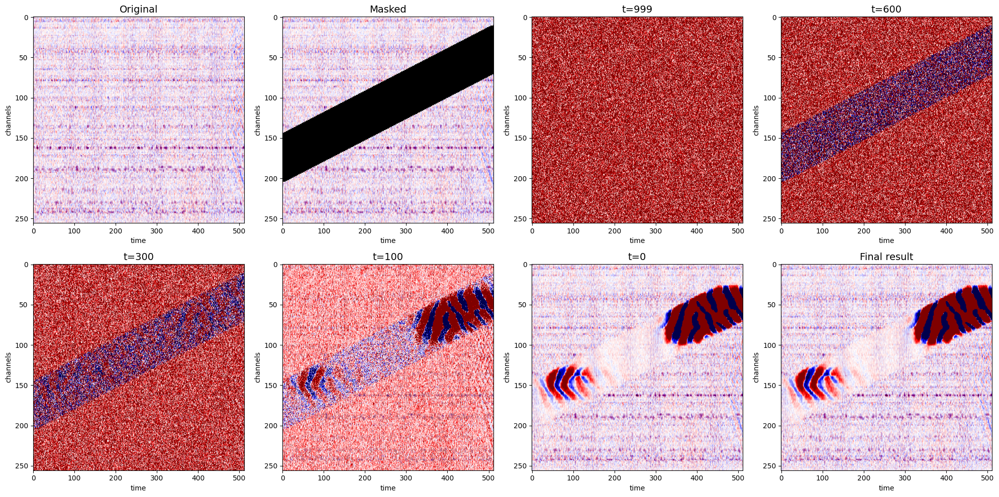

In [17]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result6)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps6):

    snap_denorm = denormalize(snaps6[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jump_n_sample=2

In [15]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result7, snaps7, times7 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=2, steps_to_save=[999, 600, 300, 100, 0])

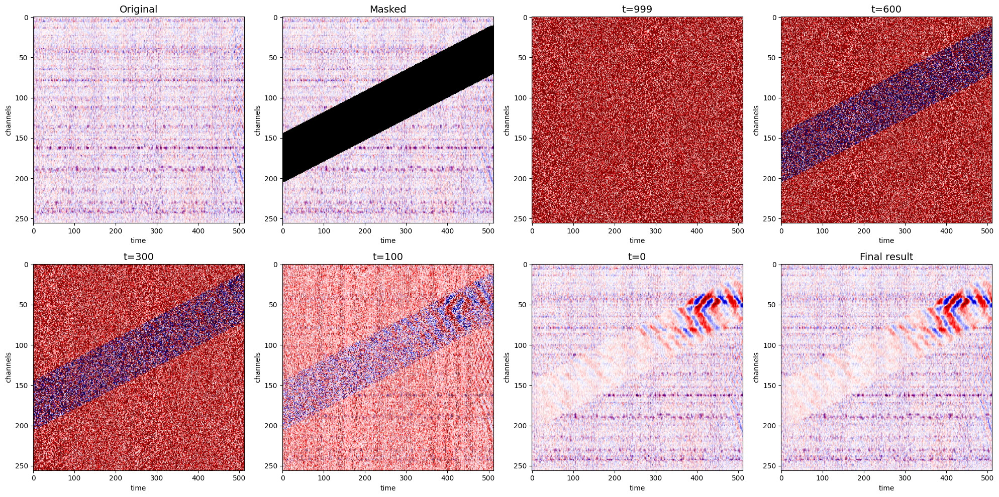

In [16]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result7)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps7):

    snap_denorm = denormalize(snaps7[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jum_n_sample=1

In [ ]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result8, snaps8, times8 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=1, steps_to_save=[999, 600, 300, 100, 0])

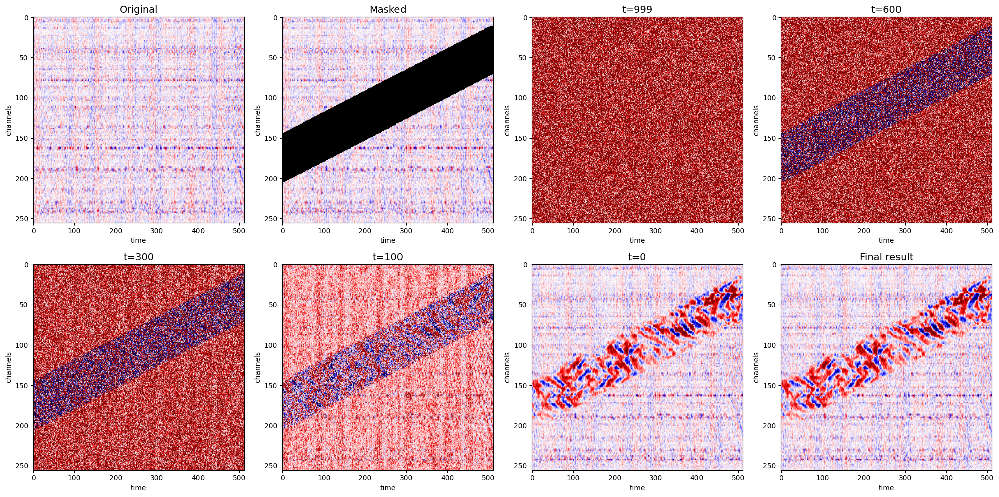

In [18]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result8)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps8):

    snap_denorm = denormalize(snaps8[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()